In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"C:\Users\saris\OneDrive\Desktop\Sales and customer_behavior_analytics\sales_cleaned.csv",sep=";")

In [3]:
df

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id
0,ORD002157,CUST00432,Kids Tricycle,Toys,2508.44,1,25,2023-07-05,Bangalore,Mobile Wallet,4.0,1
1,ORD001371,CUST00578,Badminton Racket,Sports,3259.07,1,0,2024-12-23,Chennai,Debit Card,8.0,2
2,ORD003154,CUST00718,Air Fryer,Home & kitchen,14184.28,2,5,2024-05-09,Mumbai,Credit Card,8.0,3
3,ORD000485,CUST00698,Self-Help Book,Books,533.69,1,5,2023-08-26,Mumbai,Cash on Delivery,7.0,4
4,ORD000176,CUST00676,Cookbook,Books,1741.39,1,5,2024-05-09,Delhi,eSewa,4.0,5
...,...,...,...,...,...,...,...,...,...,...,...,...
3205,ORD001684,CUST00575,Yoga Mat,Sports,7611.52,1,15,2023-02-06,Lahore,Cash on Delivery,2.0,3388
3206,ORD000355,CUST00383,Academic Textbook,Books,224.78,1,25,2024-06-17,Chennai,eSewa,9.0,3389
3207,ORD002483,CUST00034,Bed Sheet Set,Home & kitchen,13830.20,1,0,2023-08-15,Pokhara,eSewa,2.0,3390
3208,ORD000414,CUST00582,Action Figure,Toys,2896.43,5,0,2024-05-24,Karachi,Credit Card,11.0,3391


### Phase1:Data validation

In [4]:
## check the shape

In [5]:
df.shape

(3210, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3210 entries, 0 to 3209
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        3210 non-null   object 
 1   Customer ID     3210 non-null   object 
 2   Product         3210 non-null   object 
 3   Category        3210 non-null   object 
 4   Price           3210 non-null   float64
 5   Quantity        3210 non-null   int64  
 6   Discount        3210 non-null   int64  
 7   Order Date      3172 non-null   object 
 8   Region          3210 non-null   object 
 9   Payment Method  3210 non-null   object 
 10  Delivery Time   3210 non-null   float64
 11  id              3210 non-null   int64  
dtypes: float64(2), int64(3), object(7)
memory usage: 301.1+ KB


In [7]:
df.isnull().sum()

Order ID           0
Customer ID        0
Product            0
Category           0
Price              0
Quantity           0
Discount           0
Order Date        38
Region             0
Payment Method     0
Delivery Time      0
id                 0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
### order date is in object converting it to datetime

In [10]:
df["Order Date"]=pd.to_datetime(df["Order Date"],errors="coerce")

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3210 entries, 0 to 3209
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        3210 non-null   object        
 1   Customer ID     3210 non-null   object        
 2   Product         3210 non-null   object        
 3   Category        3210 non-null   object        
 4   Price           3210 non-null   float64       
 5   Quantity        3210 non-null   int64         
 6   Discount        3210 non-null   int64         
 7   Order Date      3129 non-null   datetime64[ns]
 8   Region          3210 non-null   object        
 9   Payment Method  3210 non-null   object        
 10  Delivery Time   3210 non-null   float64       
 11  id              3210 non-null   int64         
dtypes: datetime64[ns](1), float64(2), int64(3), object(6)
memory usage: 301.1+ KB


In [12]:
df["Order Date"].isna().sum()

np.int64(81)

In [13]:
df.isnull().sum()

Order ID           0
Customer ID        0
Product            0
Category           0
Price              0
Quantity           0
Discount           0
Order Date        81
Region             0
Payment Method     0
Delivery Time      0
id                 0
dtype: int64

In [14]:
# before deleting inspecting all those 81 datas returns true/NAT for invalid or missing data

In [15]:
df[df["Order Date"].isna()]

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id
57,ORD002307,CUST00074,Kids Tricycle,Toys,1731.11,2,10,NaT,Lahore,Cash on Delivery,10.0,58
65,ORD000386,CUST00242,Non-Stick Pan,Home & kitchen,7248.97,1,0,NaT,Lahore,Credit Card,3.0,66
116,ORD000377,CUST00070,Badminton Racket,Sports,6789.85,2,20,NaT,Chittagong,Debit Card,6.0,117
130,ORD000399,CUST00854,Formal Shirt,Fashion,3556.18,-1,0,NaT,Karachi,Cash on Delivery,1.0,131
164,ORD000488,CUST00306,Self-Help Book,Books,1162.50,3,20,NaT,Bangalore,UPI,8.0,166
...,...,...,...,...,...,...,...,...,...,...,...,...
2934,ORD002768,CUST00533,Green Tea Pack,Grocery,2256.60,1,15,NaT,Pokhara,Cash on Delivery,6.0,3081
2945,ORD000263,CUST00736,Fiction Novel,Books,1320.48,4,0,NaT,Kathmandu,Cash on Delivery,6.0,3093
3025,ORD000927,CUST00595,LED TV,Electronics,84486.86,3,30,NaT,Pokhara,Cash on Delivery,10.0,3183
3101,ORD000953,CUST00063,Green Tea Pack,Grocery,490.00,3,10,NaT,Dhaka,Mobile Wallet,7.0,3269


In [16]:
# original invalid data

In [17]:
df[df["Order Date"].isna()].shape

(81, 12)

In [18]:
### we will keep the 81 NaT row as it is

## Phase2:Feature Engineering

In [19]:
# creating the revenue

In [20]:
df["revenue"]=df["Price"]*df["Quantity"]*(1-df["Discount"]/100)

In [21]:
df.head(10)

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id,revenue
0,ORD002157,CUST00432,Kids Tricycle,Toys,2508.44,1,25,2023-07-05,Bangalore,Mobile Wallet,4.0,1,1881.3300
1,ORD001371,CUST00578,Badminton Racket,Sports,3259.07,1,0,2024-12-23,Chennai,Debit Card,8.0,2,3259.0700
2,ORD003154,CUST00718,Air Fryer,Home & kitchen,14184.28,2,5,2024-05-09,Mumbai,Credit Card,8.0,3,26950.1320
3,ORD000485,CUST00698,Self-Help Book,Books,533.69,1,5,2023-08-26,Mumbai,Cash on Delivery,7.0,4,507.0055
4,ORD000176,CUST00676,Cookbook,Books,1741.39,1,5,2024-05-09,Delhi,eSewa,4.0,5,1654.3205
5,ORD000189,CUST00767,Children's Storybook,Books,505.62,1,0,2023-11-14,Delhi,Credit Card,4.0,6,505.6200
6,ORD001659,CUST00243,Children's Storybook,Books,0.00,1,50,2023-12-10,Delhi,Credit Card,2.0,7,0.0000
7,ORD002802,CUST00848,Women's Kurti,Fashion,4197.97,4,20,2024-06-22,Pokhara,Mobile Wallet,9.0,8,13433.5040
8,ORD001532,CUST00749,Children's Storybook,Books,991.53,2,20,2023-07-03,Pokhara,Cash on Delivery,9.0,9,1586.4480
9,ORD000346,CUST00532,Smartphone,Electronics,48626.61,1,10,2023-02-07,Karachi,Debit Card,8.0,10,43763.9490


In [22]:
# create month number

In [23]:
df["Month"]=df["Order Date"].dt.month

In [24]:
# verifying it

In [25]:
df[["Order Date","Month"]].head()

,Order Date,Month
0,2023-07-05,7.0
1,2024-12-23,12.0
2,2024-05-09,5.0
3,2023-08-26,8.0
4,2024-05-09,5.0


In [26]:
## creating the month name

In [27]:
df["Month Name"]=df["Order Date"].dt.month_name()

In [28]:
df[["Order Date","Month Name"]].head()

,Order Date,Month Name
0,2023-07-05,July
1,2024-12-23,December
2,2024-05-09,May
3,2023-08-26,August
4,2024-05-09,May


In [29]:
df[["Order Date","Month Name","Month"]].head()

,Order Date,Month Name,Month
0,2023-07-05,July,7.0
1,2024-12-23,December,12.0
2,2024-05-09,May,5.0
3,2023-08-26,August,8.0
4,2024-05-09,May,5.0


In [30]:
# creating the year

In [31]:
df["Year"]=df["Order Date"].dt.year

In [32]:
df[["Order Date","Month Name","Month","Year"]].head()

,Order Date,Month Name,Month,Year
0,2023-07-05,July,7.0,2023.0
1,2024-12-23,December,12.0,2024.0
2,2024-05-09,May,5.0,2024.0
3,2023-08-26,August,8.0,2023.0
4,2024-05-09,May,5.0,2024.0


In [33]:
# creating quater as many company analysis sales by quater too and divide one year into 4 quater

In [34]:
df["Quarter"]=df["Order Date"].dt.quarter

In [35]:
df[["Order Date","Month Name","Month","Year","Quarter"]].head()

,Order Date,Month Name,Month,Year,Quarter
0,2023-07-05,July,7.0,2023.0,3.0
1,2024-12-23,December,12.0,2024.0,4.0
2,2024-05-09,May,5.0,2024.0,2.0
3,2023-08-26,August,8.0,2023.0,3.0
4,2024-05-09,May,5.0,2024.0,2.0


In [36]:
# creating the dayname to understand which day receive more orders

In [37]:
df["Day Name"]=df["Order Date"].dt.day_name()

In [38]:
df[["Order Date","Day Name"]].head()

,Order Date,Day Name
0,2023-07-05,Wednesday
1,2024-12-23,Monday
2,2024-05-09,Thursday
3,2023-08-26,Saturday
4,2024-05-09,Thursday


In [39]:
df.head()

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id,revenue,Month,Month Name,Year,Quarter,Day Name
0,ORD002157,CUST00432,Kids Tricycle,Toys,2508.44,1,25,2023-07-05,Bangalore,Mobile Wallet,4.0,1,1881.3300,7.0,July,2023.0,3.0,Wednesday
1,ORD001371,CUST00578,Badminton Racket,Sports,3259.07,1,0,2024-12-23,Chennai,Debit Card,8.0,2,3259.0700,12.0,December,2024.0,4.0,Monday
2,ORD003154,CUST00718,Air Fryer,Home & kitchen,14184.28,2,5,2024-05-09,Mumbai,Credit Card,8.0,3,26950.1320,5.0,May,2024.0,2.0,Thursday
3,ORD000485,CUST00698,Self-Help Book,Books,533.69,1,5,2023-08-26,Mumbai,Cash on Delivery,7.0,4,507.0055,8.0,August,2023.0,3.0,Saturday
4,ORD000176,CUST00676,Cookbook,Books,1741.39,1,5,2024-05-09,Delhi,eSewa,4.0,5,1654.3205,5.0,May,2024.0,2.0,Thursday


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3210 entries, 0 to 3209
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        3210 non-null   object        
 1   Customer ID     3210 non-null   object        
 2   Product         3210 non-null   object        
 3   Category        3210 non-null   object        
 4   Price           3210 non-null   float64       
 5   Quantity        3210 non-null   int64         
 6   Discount        3210 non-null   int64         
 7   Order Date      3129 non-null   datetime64[ns]
 8   Region          3210 non-null   object        
 9   Payment Method  3210 non-null   object        
 10  Delivery Time   3210 non-null   float64       
 11  id              3210 non-null   int64         
 12  revenue         3210 non-null   float64       
 13  Month           3129 non-null   float64       
 14  Month Name      3129 non-null   object        
 15  Year

## EDA

#### Which product categories generate the highest revenue?

In [41]:
category_revenue=(
    df.groupby("Category")["revenue"]
        .sum().sort_values(ascending=False)
)

    

In [42]:
category_revenue

Category
Electronics       2.509758e+08
Fashion           8.410281e+06
Home & kitchen    4.282172e+06
Sports            3.006580e+06
Toys              2.631873e+06
Books             1.141223e+06
Beauty            8.808674e+05
Grocery           8.752938e+05
Name: revenue, dtype: float64

In [43]:
#  histogram for revenue vs no of orders

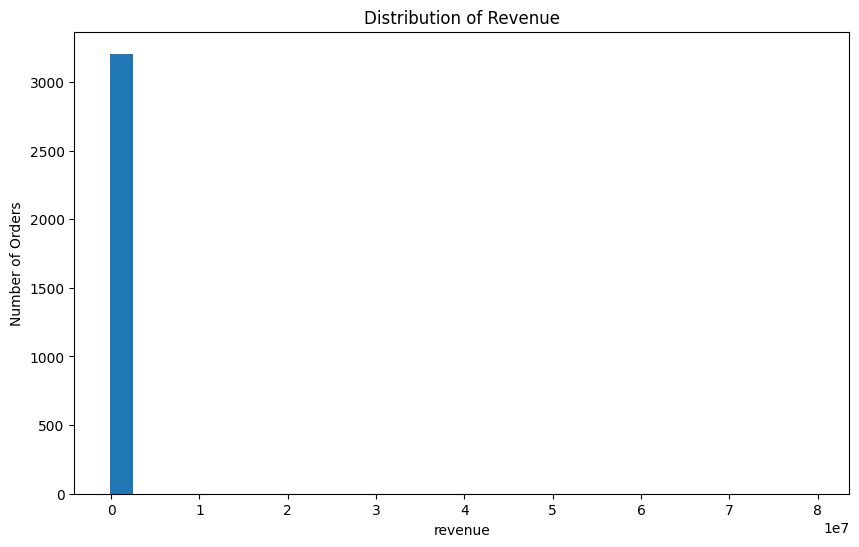

In [44]:
plt.figure(figsize=(10,6))
plt.hist(df["revenue"],bins=30)
plt.title("Distribution of Revenue")
plt.xlabel("revenue")
plt.ylabel('Number of Orders')
plt.show()

In [45]:
df["revenue"].describe()

count    3.210000e+03
mean     8.479879e+04
std      2.103398e+06
min     -1.619679e+05
25%      1.098115e+03
50%      2.872588e+03
75%      8.523778e+03
max      7.959198e+07
Name: revenue, dtype: float64

In [46]:
df["revenue"].nlargest(10)

32      7.959198e+07
2950    6.539001e+07
1356    5.170119e+07
828     2.980828e+07
274     6.487922e+06
2003    1.473231e+06
2962    6.854011e+05
2140    4.372558e+05
555     4.356839e+05
1631    3.523936e+05
Name: revenue, dtype: float64

In [47]:
df.nlargest(10, "revenue")

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id,revenue,Month,Month Name,Year,Quarter,Day Name
32,ORD000431,CUST00464,Bluetooth Speaker,Electronics,44168.69,1802,0,2023-06-15,Mumbai,Cash on Delivery,6.0,33,7.959198e+07,6.0,June,2023.0,2.0,Thursday
2950,ORD002577,CUST00532,Home Theater System,Electronics,69020.49,1579,40,2023-06-20,Chennai,eSewa,1.0,3099,6.539001e+07,6.0,June,2023.0,2.0,Tuesday
1356,ORD002805,CUST00273,Smartwatch,Electronics,89954.22,605,5,2023-11-22,Dhaka,Debit Card,8.0,1381,5.170119e+07,11.0,November,2023.0,4.0,Wednesday
828,ORD002996,CUST00837,Home Theater System,Electronics,20250.19,1472,0,2023-10-26,Dhaka,Credit Card,10.0,839,2.980828e+07,10.0,October,2023.0,4.0,Thursday
274,ORD002060,CUST00404,Running Shoes,Fashion,5651.50,1148,0,2023-07-05,Mumbai,Credit Card,1.0,276,6.487922e+06,7.0,July,2023.0,3.0,Wednesday
2003,ORD002001,CUST00409,Action Figure,Toys,2368.92,691,10,2023-01-24,Lahore,Debit Card,10.0,2065,1.473231e+06,1.0,January,2023.0,1.0,Tuesday
2962,ORD002896,CUST00784,Academic Textbook,Books,909.02,754,0,2023-02-14,Pokhara,Cash on Delivery,1.0,3112,6.854011e+05,2.0,February,2023.0,1.0,Tuesday
2140,ORD003026,CUST00676,Laptop,Electronics,87451.16,5,0,2023-12-27,Chittagong,Credit Card,1.0,2213,4.372558e+05,12.0,December,2023.0,4.0,Wednesday
555,ORD001762,CUST00514,Power Bank,Electronics,87136.77,5,0,2023-11-27,Chittagong,Debit Card,3.0,562,4.356839e+05,11.0,November,2023.0,4.0,Monday
1631,ORD002735,CUST00536,Wireless Earbuds,Electronics,88098.41,4,0,2023-09-26,Chittagong,Credit Card,5.0,1675,3.523936e+05,9.0,September,2023.0,3.0,Tuesday


In [48]:
df.nsmallest(10, "revenue")

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id,revenue,Month,Month Name,Year,Quarter,Day Name
3165,ORD001073,CUST00820,Smartphone,Electronics,80983.96,-2,0,2023-02-26,Chennai,UPI,5.0,3343,-161967.920,2.0,February,2023.0,1.0,Sunday
2322,ORD001853,CUST00815,Smartphone,Electronics,60062.28,-3,15,2023-03-19,Pokhara,UPI,3.0,2419,-153158.814,3.0,March,2023.0,1.0,Sunday
3204,ORD002218,CUST00249,LED TV,Electronics,86465.93,-1,0,2024-11-17,Kathmandu,Cash on Delivery,2.0,3387,-86465.930,11.0,November,2024.0,4.0,Sunday
2849,ORD000158,CUST00532,Wireless Earbuds,Electronics,53403.40,-2,25,2023-11-10,Chittagong,Debit Card,3.0,2990,-80105.100,11.0,November,2023.0,4.0,Friday
188,ORD002124,CUST00429,Power Bank,Electronics,33806.98,-2,5,2023-10-03,Bangalore,Mobile Wallet,1.0,190,-64233.262,10.0,October,2023.0,4.0,Tuesday
3150,ORD002340,CUST00126,Bluetooth Speaker,Electronics,64218.60,-1,0,2023-06-02,Mumbai,Cash on Delivery,2.0,3322,-64218.600,6.0,June,2023.0,2.0,Friday
2073,ORD001904,CUST00514,Laptop,Electronics,63143.70,-1,0,2023-12-09,Chittagong,Cash on Delivery,11.0,2140,-63143.700,12.0,December,2023.0,4.0,Saturday
1248,ORD001027,CUST00234,LED TV,Electronics,25317.10,-2,0,2024-12-16,Bangalore,UPI,9.0,1270,-50634.200,12.0,December,2024.0,4.0,Monday
657,ORD002635,CUST00513,Wireless Earbuds,Electronics,37143.60,-1,15,2023-07-15,Delhi,Mobile Wallet,9.0,664,-31572.060,7.0,July,2023.0,3.0,Saturday
1523,ORD001712,CUST00140,Bed Sheet Set,Home & kitchen,14522.86,-2,0,2023-03-09,Mumbai,Mobile Wallet,11.0,1557,-29045.720,3.0,March,2023.0,1.0,Thursday


In [49]:
# counting negative dataset

In [50]:
(df["Quantity"] < 0).sum()

np.int64(96)

In [51]:
df[df["Quantity"] < 0]

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id,revenue,Month,Month Name,Year,Quarter,Day Name
35,ORD003068,CUST00204,Ceramic Dinner Set,Home & kitchen,11982.72,-2,20,2023-11-13,Lahore,Mobile Wallet,4.0,36,-19172.352,11.0,November,2023.0,4.0,Monday
41,ORD002908,CUST00465,Remote Control Car,Toys,4055.29,-1,0,2024-10-18,Pokhara,Debit Card,4.0,42,-4055.290,10.0,October,2024.0,4.0,Friday
44,ORD002048,CUST00566,Building Blocks Set,Toys,395.33,-2,0,2023-08-15,Mumbai,eSewa,8.0,45,-790.660,8.0,August,2023.0,3.0,Tuesday
78,ORD000193,CUST00034,Fiction Novel,Books,1744.30,-1,15,2023-12-10,Delhi,Cash on Delivery,3.0,79,-1482.655,12.0,December,2023.0,4.0,Sunday
122,ORD001304,CUST00092,Puzzle Game,Toys,1147.42,-1,0,2023-04-02,Mumbai,Debit Card,9.0,123,-1147.420,4.0,April,2023.0,2.0,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3165,ORD001073,CUST00820,Smartphone,Electronics,80983.96,-2,0,2023-02-26,Chennai,UPI,5.0,3343,-161967.920,2.0,February,2023.0,1.0,Sunday
3188,ORD001089,CUST00140,Blender,Home & kitchen,10564.83,-1,0,2023-02-21,Mumbai,Credit Card,8.0,3368,-10564.830,2.0,February,2023.0,1.0,Tuesday
3189,ORD003036,CUST00499,Soft Teddy Bear,Toys,898.44,-2,10,2023-05-14,Chittagong,Cash on Delivery,9.0,3369,-1617.192,5.0,May,2023.0,2.0,Sunday
3194,ORD002575,CUST00575,Children's Storybook,Books,1568.90,-1,30,2024-05-27,Delhi,Credit Card,5.0,3375,-1098.230,5.0,May,2024.0,2.0,Monday


In [52]:
# Removing records with negative quantities.
# Since this project analyzes sales transactions only,
# negative quantities are treated as invalid records.

In [53]:
df = df[df["Quantity"] > 0]

In [54]:
df.shape

(3114, 18)

In [55]:
# there is no data with negative quantity
df[df["Quantity"] < 0]

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id,revenue,Month,Month Name,Year,Quarter,Day Name


In [56]:
#  again looking for the invalid date as previously we had 81 and some invalid date might included in negative quantity too so checking the shape

In [57]:
df["Order Date"].isna().sum()

np.int64(79)

In [58]:
# identifying the outlier in quantity using q1,q3

In [59]:
Q1 = df["Quantity"].quantile(0.25)
Q3 = df["Quantity"].quantile(0.75)

print("Q1:", Q1)
print("Q3:", Q3)

Q1: 1.0
Q3: 2.0


In [60]:
Lower Limit:

Q1−1.5×IQR

Upper Limit:

Q3+1.5×IQR


IQR=Q3−Q1=2−1=1


SyntaxError: invalid character '−' (U+2212) (4039681459.py, line 3)

In [ ]:
Lower Limit

Formula:

Q1−1.5×IQR

Substitute the values:

1−1.5×1

First calculate:

1.5×1=1.5

Then:

1−1.5=−0.5

So,Lower Limit = -0.5


Upper Limit
Formula:

Q3+1.5×IQR

Substitute the values:

2+1.5×1
2+1.5=3.5

So,Upper Limit = 3.5

In [ ]:
# using IQR method to find outliers

In [ ]:
outliers = df[(df["Quantity"] < -0.5) | (df["Quantity"] > 3.5)]

print("Number of potential outliers:", len(outliers))

In [ ]:
#"The IQR method identified 203 potential outliers in the Quantity column.
#However, many represented legitimate purchases (e.g., quantities of 4 or 5). Therefore, instead of removing all statistical outliers, business context was considered, and only extreme values were investigated."

### Python EDA

#### Does our Revenue contain extreme values (outliers)?

In [ ]:
# to find the outliers we will use boxplot

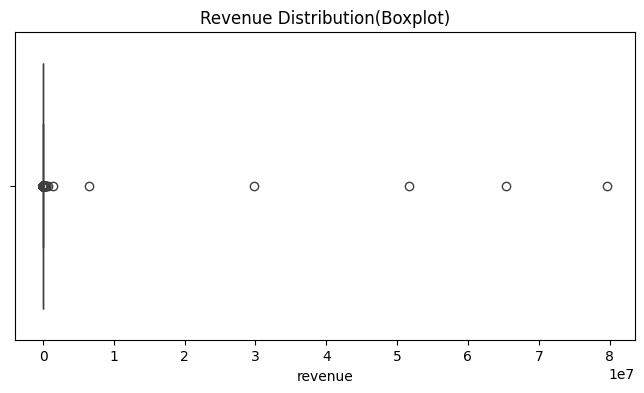

In [61]:
plt.figure(figsize=(8,4))
sns.boxplot(x=df["revenue"])
plt.title("Revenue Distribution(Boxplot)")
plt.xlabel("revenue")
plt.show()
            

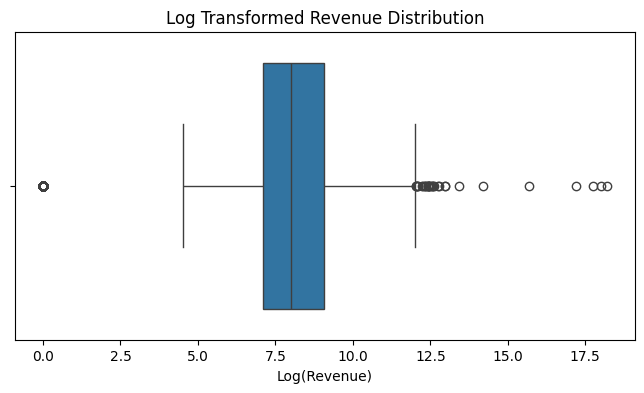

In [62]:
plt.figure(figsize=(8,4))

sns.boxplot(x=np.log1p(df["revenue"]))

plt.title("Log Transformed Revenue Distribution")
plt.xlabel("Log(Revenue)")

plt.show()

In [63]:
#Revenue is highly right-skewed. Most orders generate relatively low revenue, while a small number of orders contribute exceptionally high revenue,
#indicating the presence of high-value transactions.

#### "How did revenue change over time?"

In [64]:
monthly_revenue=(
    df.groupby("Month Name")["revenue"].sum()
    .reindex(["January","February","March","April","May","June","July","August",
              "September","October","November","December"])
)
    

In [65]:
monthly_revenue

Month Name
January      3.886076e+06
February     2.834331e+06
March        3.421196e+06
April        2.171632e+06
May          2.667417e+06
June         1.478944e+08
July         9.606731e+06
August       2.506577e+06
September    2.788669e+06
October      3.365680e+07
November     5.710967e+07
December     3.848806e+06
Name: revenue, dtype: float64

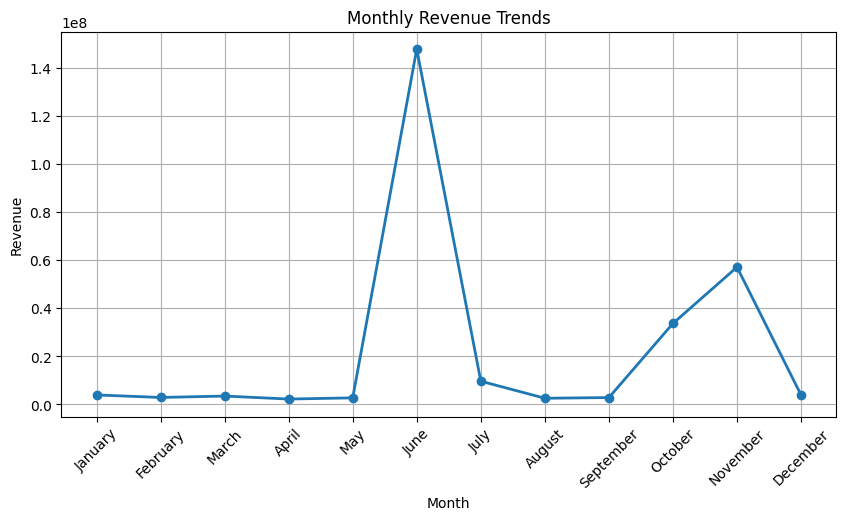

In [66]:
plt.figure(figsize=(10,5))
plt.plot(monthly_revenue.index,
        monthly_revenue.values,
        marker="o",
        linewidth=2)
plt.title("Monthly Revenue Trends")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

#### Which product category generated the highest revenue?

In [67]:
category_revenue=(
    df.groupby("Category")["revenue"].sum()
    .sort_values(ascending=False)
)


In [68]:
category_revenue

Category
Electronics       2.517962e+08
Fashion           8.449966e+06
Home & kitchen    4.379683e+06
Sports            3.119345e+06
Toys              2.688974e+06
Books             1.153916e+06
Beauty            9.028123e+05
Grocery           8.873613e+05
Name: revenue, dtype: float64

In [69]:
# showing in bar chart

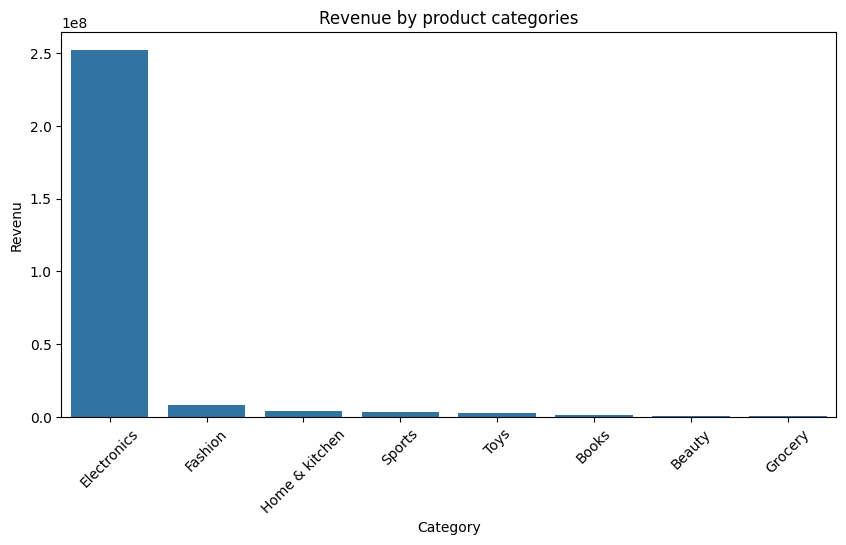

In [70]:
plt.figure(figsize=(10,5))
sns.barplot(
    x=category_revenue.index,
    y=category_revenue.values
)
plt.title("Revenue by product categories")
plt.xlabel("Category")
plt.ylabel("Revenu")
plt.xticks(rotation=45)
plt.show()

#### Which payment method is used the most by customers?

In [79]:
payment_counts=df["Payment Method"].value_counts()
payment_counts

Payment Method
Mobile Wallet       556
eSewa               540
Cash on Delivery    525
Credit Card         502
Debit Card          497
UPI                 494
Name: count, dtype: int64

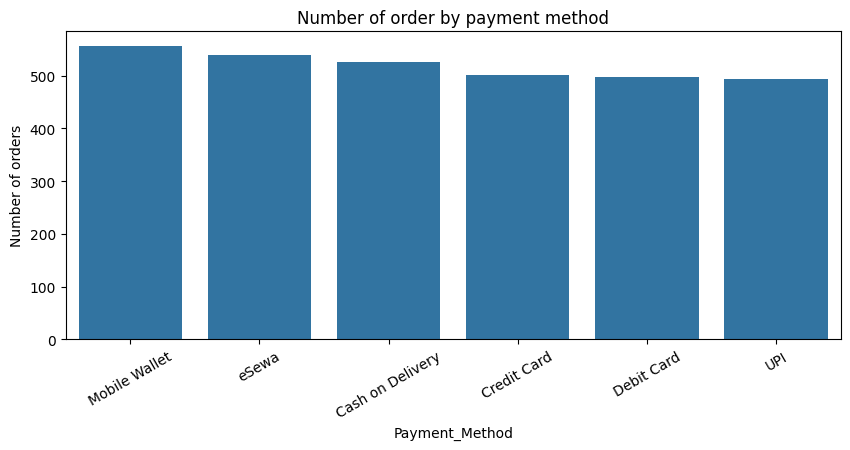

In [80]:
plt.figure(figsize=(10,4))
sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values
)
plt.title("Number of order by payment method")
plt.xlabel("Payment_Method")
plt.ylabel("Number of orders")
plt.xticks(rotation=30)
plt.show()

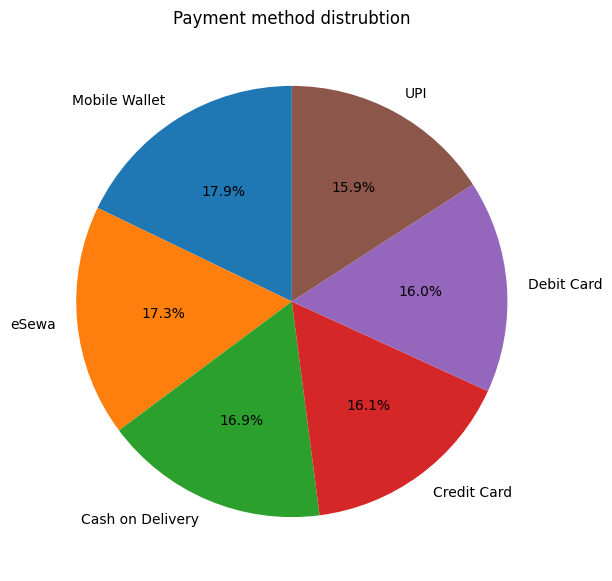

In [81]:
plt.figure(figsize=(7,7))
plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct= "%1.1f%%",
    startangle=90
)
plt.title("Payment method distrubtion")
plt.show()

In [82]:
#"Seaborn doesn't provide a pie() function. Pie charts are created using Matplotlib's plt.pie(), while Seaborn is mainly designed for statistical visualizations like bar plots, histograms, boxplots, scatter plots, and heatmaps."

In [83]:
df["Payment Method"].unique()

array(['Mobile Wallet', 'Debit Card', 'Credit Card', 'Cash on Delivery',
       'eSewa', 'UPI'], dtype=object)

In [84]:
df["Payment Method"].value_counts()

Payment Method
Mobile Wallet       556
eSewa               540
Cash on Delivery    525
Credit Card         502
Debit Card          497
UPI                 494
Name: count, dtype: int64

In [85]:
df["Payment Method"] = df["Payment Method"].replace({
    "credit card": "Credit Card",
    "CREDIT CARD": "Credit Card",
    "Credit Card":"Credit Card"
})

C:\Users\saris\AppData\Local\Temp\ipykernel_17796\2656888246.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["Payment Method"] = df["Payment Method"].replace({


In [86]:
df["Payment Method"]

0          Mobile Wallet
1             Debit Card
2            Credit Card
3       Cash on Delivery
4                  eSewa
              ...       
3205    Cash on Delivery
3206               eSewa
3207               eSewa
3208         Credit Card
3209          Debit Card
Name: Payment Method, Length: 3114, dtype: object

In [87]:
df["Payment Method"].value_counts()

Payment Method
Mobile Wallet       556
eSewa               540
Cash on Delivery    525
Credit Card         502
Debit Card          497
UPI                 494
Name: count, dtype: int64

In [88]:
#Mobile Wallet was the most preferred payment method,
#followed closely by eSewa and Cash on Delivery. 
#However, the difference among all payment methods is relatively small, suggesting that customers use a variety of payment options rather than relying on a single method.

#### Which region generated the highest revenue?

In [89]:
region_revenue=(
    df.groupby("Region")["revenue"].sum()
    .sort_values(ascending=False)
)
region_revenue
    

Region
Mumbai        8.946584e+07
Dhaka         8.600921e+07
Chennai       6.885627e+07
Lahore        5.421140e+06
Chittagong    4.784096e+06
Pokhara       4.314933e+06
Karachi       3.944339e+06
Bangalore     3.750179e+06
Delhi         3.490733e+06
Kathmandu     3.341573e+06
Name: revenue, dtype: float64

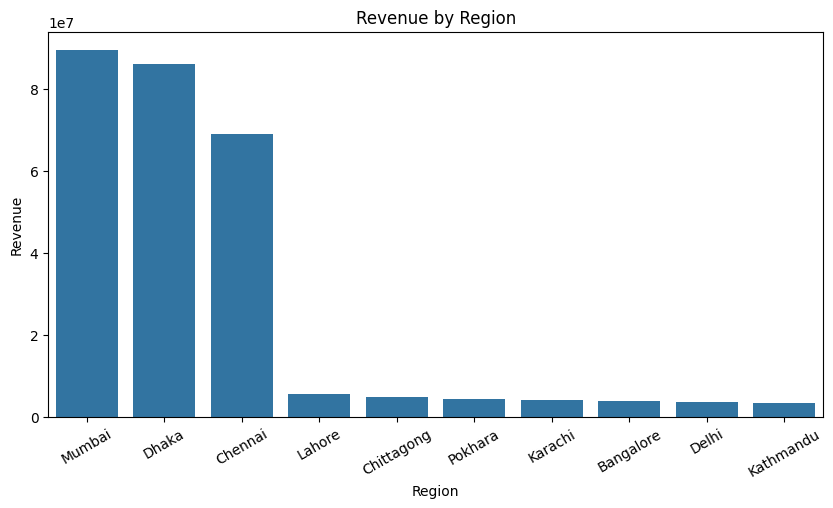

In [90]:
plt.figure(figsize=(10,5))
sns.barplot(
    x=region_revenue.index,
    y=region_revenue.values
)
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.show()

In [91]:
#"Mumbai generated the highest revenue, followed closely by Dhaka and Chennai. These three regions contribute a much larger share of total revenue than the remaining regions, 
#indicating that they are the company's strongest markets."

#### Which day of the week generates the highest revenue?

In [92]:
day_revenue=(
    df.groupby("Day Name")["revenue"].sum()
    .reindex(["Sunday","Monday","Tuesday","Wednesday",
              "Thursday","Friday","Saturday"])
)
day_revenue

Day Name
Sunday       4.940886e+06
Monday       5.303917e+06
Tuesday      7.306987e+07
Wednesday    6.359781e+07
Thursday     1.156211e+08
Friday       5.042885e+06
Saturday     4.815924e+06
Name: revenue, dtype: float64

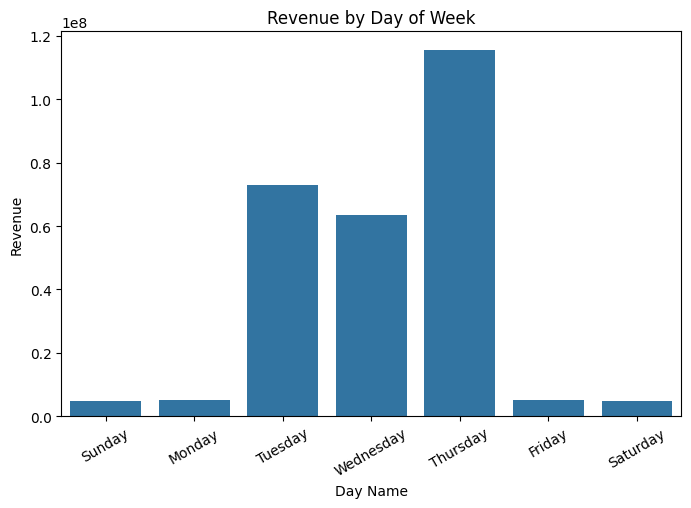

In [93]:
plt.figure(figsize=(8,5))
sns.barplot(
     x=day_revenue.index,
    y=day_revenue.values
)
plt.title("Revenue by Day of Week")
plt.xlabel("Day Name")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.show()

In [94]:
#Revenue is not evenly distributed throughout the week.
#Most revenue is generated on Tuesday, Wednesday, and especially Thursday,
#while the remaining days contribute significantly less. 
#This suggests that customer purchasing activity is concentrated during the middle of the week.

#### Which category performs best in each month?--using heatmap and pivot table as it reshapes the data into matrix

In [95]:
#1d summery group by
#2 dimension summaries heatmap

In [96]:
category_month = df.pivot_table(
    values="revenue",
    index="Month Name",
    columns="Category",
    aggfunc="sum"
)

In [97]:
month_order = [
    "January","February","March","April","May","June",
    "July","August","September","October","November","December"
]

category_month = category_month.reindex(month_order)

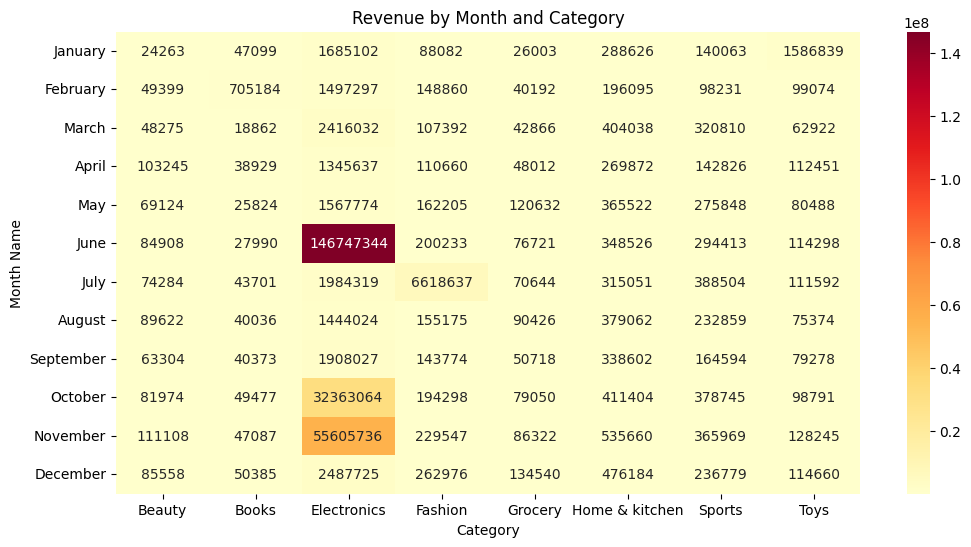

In [98]:
plt.figure(figsize=(12,6))

sns.heatmap(
    category_month,
    annot=True,
    fmt=".0f", # format it represent number without decimal points
    cmap="YlOrRd" #color map
)

plt.title("Revenue by Month and Category")
plt.show()

#### Does giving higher discounts increase revenue?

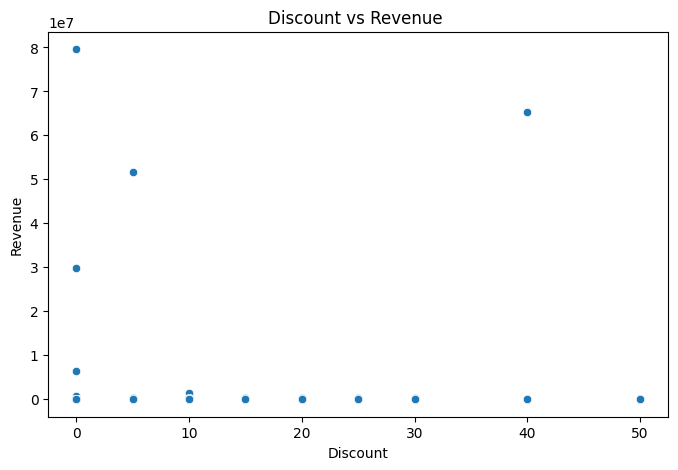

In [99]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="Discount",
    y="revenue",
    data=df
)
plt.title("Discount vs Revenue ")
plt.xlabel("Discount")
plt.ylabel("Revenue")
#plt.yscale("log")
plt.show()
           

In [100]:
#The scatter plot does not show a clear relationship between discount
#and revenue. High-revenue orders occur at different discount levels,
#suggesting that discount alone does not determine revenue. 
#Other factors such as product price, quantity sold, 
#and product category likely have a stronger influence on revenue.

#### Does delivery time affect revenue?

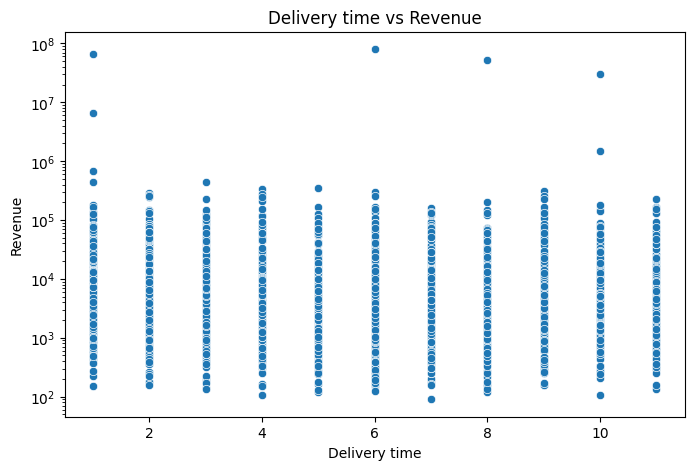

In [101]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="Delivery Time",
    y="revenue",
    data=df
)
plt.title("Delivery time vs Revenue")
plt.xlabel("Delivery time")
plt.ylabel("Revenue")
plt.yscale("log")
plt.show()
    

In [102]:
#There is no clear relationship between delivery time and revenue. 
#Orders with both high and low revenue occur across different delivery times. 
#This suggests that delivery time alone does not significantly influence
#revenue. Other factors such as product category, product price,
#and quantity sold are likely to have a greater impact.

#### Average Revenue by Delivery Time"

In [103]:
delivery_revenue=(
    df.groupby("Delivery Time")["revenue"].mean()
)

In [104]:
delivery_revenue

Delivery Time
1.0     273395.733358
2.0      13922.096133
3.0      13847.972379
4.0      14680.974401
5.0      11356.669996
6.0     241377.076244
7.0      10461.997512
8.0     201823.147913
9.0      14011.940314
10.0    119017.332779
11.0     11755.928567
Name: revenue, dtype: float64

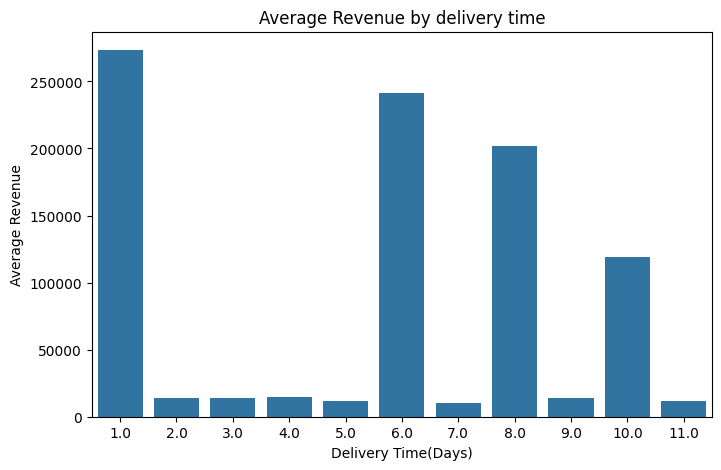

In [105]:
plt.figure(figsize=(8,5))
sns.barplot(
    x=delivery_revenue.index,
    y=delivery_revenue.values
)
plt.title("Average Revenue by delivery time")
plt.xlabel("Delivery Time(Days)")
plt.ylabel("Average Revenue")
plt.show()
            

In [106]:

# How many orders fall into each delivery time

In [107]:
df["Delivery Time"].value_counts()

Delivery Time
6.0     346
11.0    291
2.0     285
10.0    285
1.0     281
7.0     277
9.0     274
5.0     273
8.0     269
3.0     269
4.0     264
Name: count, dtype: int64

#### Which products generate the highest revenue?

In [108]:
product_revenue=(
    df.groupby("Product")["revenue"]
        .sum()
        .sort_values(ascending=False)
)
product_revenue

Product
Home Theater System     9.785388e+07
Bluetooth Speaker       8.254500e+07
Smartwatch              5.459073e+07
Running Shoes           6.704950e+06
Laptop                  4.663347e+06
Smartphone              3.677423e+06
Power Bank              3.183731e+06
Wireless Earbuds        3.006497e+06
LED TV                  2.275639e+06
Action Figure           1.678937e+06
Academic Textbook       7.832791e+05
Vacuum Cleaner          7.016445e+05
LED Table Lamp          6.645990e+05
Air Fryer               6.530337e+05
Water Bottle            5.904209e+05
Badminton Racket        5.621722e+05
Yoga Mat                5.430351e+05
Bed Sheet Set           5.208289e+05
Cycling Helmet          5.122508e+05
Ceramic Dinner Set      5.117846e+05
Football                4.776955e+05
Cricket Bat             4.274725e+05
Non-Stick Pan           4.081271e+05
Blender                 3.292438e+05
Resistance Bands        3.160173e+05
Formal Shirt            2.952495e+05
Leather Handbag         2.9306

In [109]:
top_products=product_revenue.head(10)
top_products

Product
Home Theater System    9.785388e+07
Bluetooth Speaker      8.254500e+07
Smartwatch             5.459073e+07
Running Shoes          6.704950e+06
Laptop                 4.663347e+06
Smartphone             3.677423e+06
Power Bank             3.183731e+06
Wireless Earbuds       3.006497e+06
LED TV                 2.275639e+06
Action Figure          1.678937e+06
Name: revenue, dtype: float64

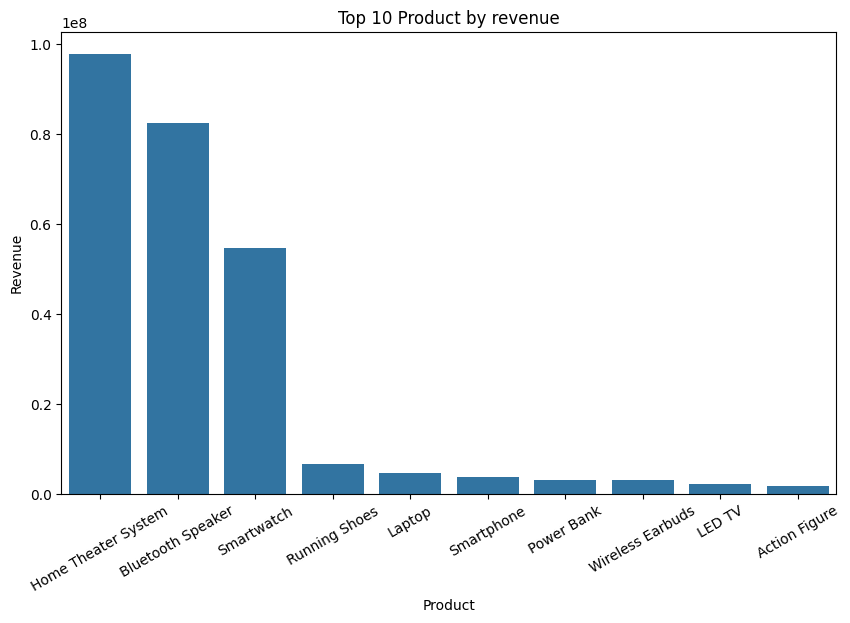

In [110]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=top_products.index,
    y=top_products.values
)
plt.title("Top 10 Product by revenue")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=30) 
plt.show()

#### Which customers contribute the most revenue?

In [111]:
customer_revenue=(
    df.groupby("Customer ID")["revenue"]
    .sum()
    .sort_values(ascending=False)
)
top_customers=customer_revenue.head(10)
top_customers

Customer ID
CUST00464    7.969745e+07
CUST00532    6.709077e+07
CUST00273    5.171067e+07
CUST00837    2.988545e+07
CUST00404    6.492103e+06
CUST00409    1.655748e+06
CUST00676    9.508967e+05
CUST00784    7.576998e+05
CUST00248    5.425177e+05
CUST00465    5.417261e+05
Name: revenue, dtype: float64

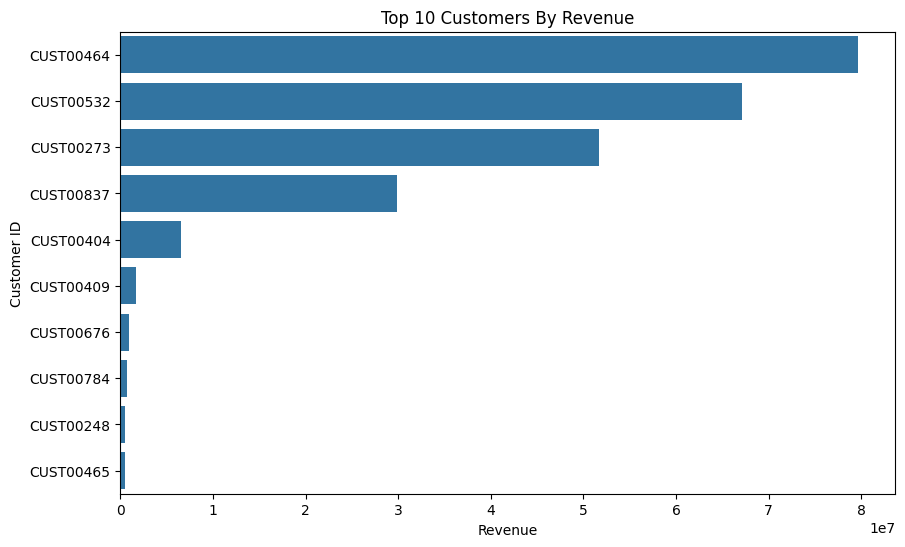

In [112]:
plt.figure(figsize=(10,6))
sns.barplot(
    x=top_customers.values,
    y=top_customers.index
)
plt.title("Top 10 Customers By Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer ID")
plt.show()

#### Should a company focus only on its top customers?

In [113]:
#The company should maintain strong relationships with high-value customers while also developing strategies to retain medium-value customers and encourage low-value customers to make repeat purchases. 
#This reduces customer concentration risk and supports sustainable long-term revenue growth.

#### How are the numerical variables related to each other?

In [114]:
df.select_dtypes(include="number").columns

Index(['Price', 'Quantity', 'Discount', 'Delivery Time', 'id', 'revenue',
       'Month', 'Year', 'Quarter'],
      dtype='object')

In [115]:
#correlation matrix
corr=df[
    ['Price', 'Quantity', 'Discount', 'Delivery Time', 'revenue',
       'Month', 'Quarter']
    ].corr()
    

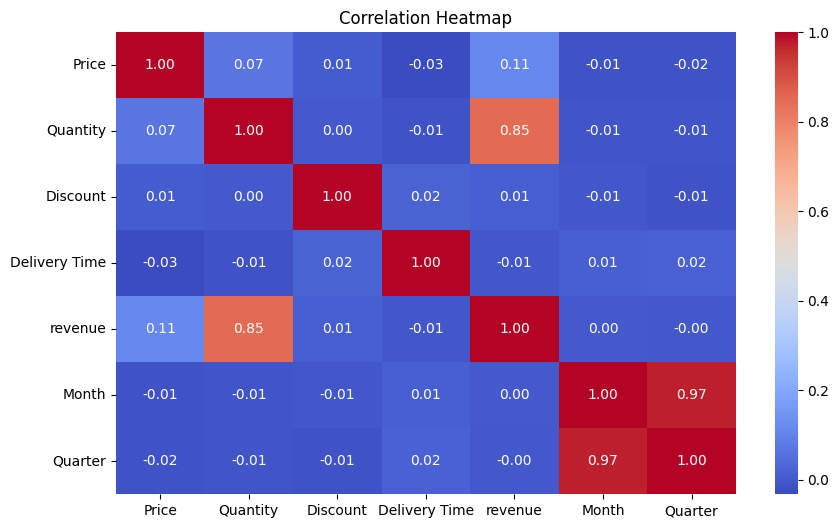

In [116]:
#create heatmap
plt.figure(figsize=(10,6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.show()

In [117]:
#The correlation analysis shows that Quantity has the strongest positive relationship with Revenue (0.85),
#indicating that selling more units significantly increases revenue. 
#Price has only a weak positive relationship (0.11), 
#suggesting that product price alone is not a strong driver of revenue.
#Discount and Delivery Time show almost no correlation with Revenue, 
#implying that these factors do not independently influence revenue in this dataset.

In [118]:
#exporting the cleaned dataset
df.to_excel("ecommerce_sales_cleaned.xlsx",index=False)

In [ ]:
df.to_csv("ecommerce_sales_cleaned.csv", index=False)

In [119]:
df

,Order ID,Customer ID,Product,Category,Price,Quantity,Discount,Order Date,Region,Payment Method,Delivery Time,id,revenue,Month,Month Name,Year,Quarter,Day Name
0,ORD002157,CUST00432,Kids Tricycle,Toys,2508.44,1,25,2023-07-05,Bangalore,Mobile Wallet,4.0,1,1881.3300,7.0,July,2023.0,3.0,Wednesday
1,ORD001371,CUST00578,Badminton Racket,Sports,3259.07,1,0,2024-12-23,Chennai,Debit Card,8.0,2,3259.0700,12.0,December,2024.0,4.0,Monday
2,ORD003154,CUST00718,Air Fryer,Home & kitchen,14184.28,2,5,2024-05-09,Mumbai,Credit Card,8.0,3,26950.1320,5.0,May,2024.0,2.0,Thursday
3,ORD000485,CUST00698,Self-Help Book,Books,533.69,1,5,2023-08-26,Mumbai,Cash on Delivery,7.0,4,507.0055,8.0,August,2023.0,3.0,Saturday
4,ORD000176,CUST00676,Cookbook,Books,1741.39,1,5,2024-05-09,Delhi,eSewa,4.0,5,1654.3205,5.0,May,2024.0,2.0,Thursday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3205,ORD001684,CUST00575,Yoga Mat,Sports,7611.52,1,15,2023-02-06,Lahore,Cash on Delivery,2.0,3388,6469.7920,2.0,February,2023.0,1.0,Monday
3206,ORD000355,CUST00383,Academic Textbook,Books,224.78,1,25,2024-06-17,Chennai,eSewa,9.0,3389,168.5850,6.0,June,2024.0,2.0,Monday
3207,ORD002483,CUST00034,Bed Sheet Set,Home & kitchen,13830.20,1,0,2023-08-15,Pokhara,eSewa,2.0,3390,13830.2000,8.0,August,2023.0,3.0,Tuesday
3208,ORD000414,CUST00582,Action Figure,Toys,2896.43,5,0,2024-05-24,Karachi,Credit Card,11.0,3391,14482.1500,5.0,May,2024.0,2.0,Friday


In [120]:
df.to_csv("ecommerce_sales_cleaned1.csv", index=False)